In [1]:
import os
import torch
import numpy as np
import pandas as pd
import torch.nn as nn
from tqdm import tqdm
import torch.optim as optim
import torch.nn.functional as F

from scipy.io import wavfile
from python_speech_features import mfcc
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, Dataset

# Tarea 4: Redes recurrentes
Objetivos
- Analizar series de tiempo y comprender las complicaciones propias de este tipo de datos.
- Estudiar el funcionamiento de las redes recurrentes.
- Evaluar el desempeño de las redes recurrentes y entender por qué difieren de las redes Feed Forward.
- Estudiar la implementación de redes LSTM.
- Comprender el concepto de tokenización.


Datos
- Trayectorias 2D: objeto RandomTrajectories (Parte 3).
- ESC-50: conjunto de datos público y etiquetado, diseñado para evaluar y comparar algoritmos de clasificación de sonidos ambientales (Parte 4).


Características principales de ESC-50
Contenido: 2.000 grabaciones de audio en formato WAV (5 segundos de duración cada una, mono, a 44,1 kHz), extraídas de Freesound.org.
- Clases y categorías: 50 clases semánticas (40 clips por clase), organizadas en 5 categorías principales:
- Animales: perros, gatos, pájaros, ranas, etc.
- Sonidos de la naturaleza y agua: lluvia, viento, olas del mar, truenos, etc.
- Sonidos humanos (sin voz): risa, tos, aplausos, llanto de bebé, etc.
- Sonidos interiores/domésticos: aspiradora, vidrio rompiéndose, teclado de computador, etc.
- Sonidos exteriores/urbanos: sirenas de policía, motor de auto, helicóptero, disparos, etc.

# Parte 1: Preguntas teóricas
1. Defina el concepto de tokenización en el contexto del procesamiento de texto.
2. Explique cómo funciona el padding en la clasificación de texto y por qué es necesario al trabajar con batches.
3. En una celda LSTM, ¿en qué se diferencian el carrier (estado de la celda, $c_t$) y el hidden state ($h_t$)?
4. Describa qué son los coeficientes MFCC (Mel-Frequency Cepstral Coefficients) en el contexto del procesamiento de audio.

# Parte 2: Definición de redes recurrentes
1. Implemente un módulo LSTM que siga las siguientes ecuaciones:
$$
\begin{aligned}
f_t &= \sigma(W_{xf}x_t + W_{hf}h_{t-1} + b_f) \\
i_t &= \sigma(W_{xi}x_t + W_{hi}h_{t-1} + b_i) \\
o_t &= \sigma(W_{xo}x_t + W_{ho}h_{t-1} + b_o) \\
\tilde{c}_t &= f_c(W_{xc}x_t + W_{hc}h_{t-1} + b_c) \\
c_t &= f_t \odot c_{t-1} + i_t \odot \tilde{c}_t \\
h_t &= o_t \odot f_h(c_t)
\end{aligned}
$$

donde $f_c$ y $f_h$ son funciones de activación (por ejemplo, $\tanh$).

2. Construya una red que apile múltiples módulos LSTM. Si trabaja con texto, se recomienda usar un módulo de embedding (nn.Embedding) para convertir los tokens en vectores antes de la primera capa LSTM.

3. Valide su módulo LSTM con la función EvaluateModule.

4. Valide su red completa con la función EvaluateNetwork.


In [3]:
class ModuleLSTM(nn.Module):
    def __init__(self, input_dim:int=20, hidden_dim:int=32, iterations:int=100):
        super(ModuleLSTM, self).__init__()
        ###### CODE HERE ######
    def forward(self, x, h, carrier):
        ###### CODE HERE ######
        return hs, carriers

class LSTMNetwork(nn.Module):
    def __init__(self, input_dim: int = 2, hidden_dim: int = 32, iterations: int = 20, output_dim: int = 2, num_layers: int = 2):
        super(LSTMNetwork, self).__init__()
        self.initial_c = nn.Parameter(torch.zeros(num_layers, hidden_dim))
        self.initial_h = nn.Parameter(torch.zeros(num_layers, hidden_dim))
        nn.init.zeros_(self.initial_c)
        nn.init.zeros_(self.initial_h)
        ###### CODE HERE ######

    def forward(self, x):
        ###### CODE HERE ######
        return h_states, pred

def EvaluateModule():
    input_dim = 10
    hidden_dim = 11
    sequence_size =12
    batch_size = 9
    model = ModuleLSTM(input_dim,hidden_dim,sequence_size)
    model.eval()
    data_sample = torch.rand(batch_size,sequence_size, input_dim)
    h = torch.zeros(batch_size, hidden_dim)
    carrier = torch.zeros(batch_size, hidden_dim)
    output, carrier = model(data_sample, h, carrier)
    assert output.size()[0] == batch_size,"Batch size should remains constant. "
    assert output.size()[1] == sequence_size,"The output of a LSTM must respect the sequence length. "
    assert output.size()[2] == hidden_dim,"Inconsistent Hidden dimension."
    assert carrier.size()[0] == batch_size,"Batch size should remains constant. "
    assert carrier.size()[1] == sequence_size,"Inconsistent Hidden dimension."
    assert carrier.size()[2] == hidden_dim,"Inconsistent Hidden dimension."

    print("Successful check for LSTM module")

def EvaluateNetwork():
    input_dim = 10
    hidden_dim = 11
    sequence_size =12
    n_classes = 13
    batch_size = 9
    model = LSTMNetwork(input_dim, hidden_dim, sequence_size, output_dim=n_classes)

    data_sample = torch.rand(batch_size,sequence_size, input_dim)
    output_seq,pred = model(data_sample)
    assert output_seq.size()[0] == batch_size
    assert output_seq.size()[1] == sequence_size
    assert output_seq.size()[2] == hidden_dim
    assert pred.size()[0] == batch_size
    assert pred.size()[1] == n_classes
    print("Successful check for LSTM Network")

EvaluateModule()
EvaluateNetwork()


Successful check for LSTM module
Successful check for LSTM Network


# Parte 3: Entrenamiento de redes recurrentes para trayectorias

El objeto RandomTrajectories genera trayectorias 2D aleatorias, que pueden ser rectas o curvas y que incluyen un poco de ruido. En esta actividad se usarán los últimos 20 puntos de una trayectoria para predecir la posición que se encuentra 3 pasos de tiempo más adelante.

1. Grafique algunos ejemplos aleatorios de RandomTrajectories.
2. Genere histogramas de la distancia en X y en Y entre el punto de partida y el punto de llegada de las trayectorias. Calcule también un promedio desviación estándar apropiados.
3. Entrene una red LSTM.
4. Entrene una red Feed Forward de al menos 10 capas. Verifique que ambos modelos tengan un número comparable de parámetros.
5. Compare las métricas de error de ambos modelos.
6. Extienda trayectorias de forma autorregresiva: durante 10 iteraciones, y para distintas trayectorias, agregue a la ventana de entrada la predicción generada por la red como nuevo último punto y vuelva a predecir.
7. ¿Qué ventajas observó en el modelo LSTM?
8. ¿En qué contextos sería útil prolongar series de tiempo a partir de predicciones (modelos generativos)?

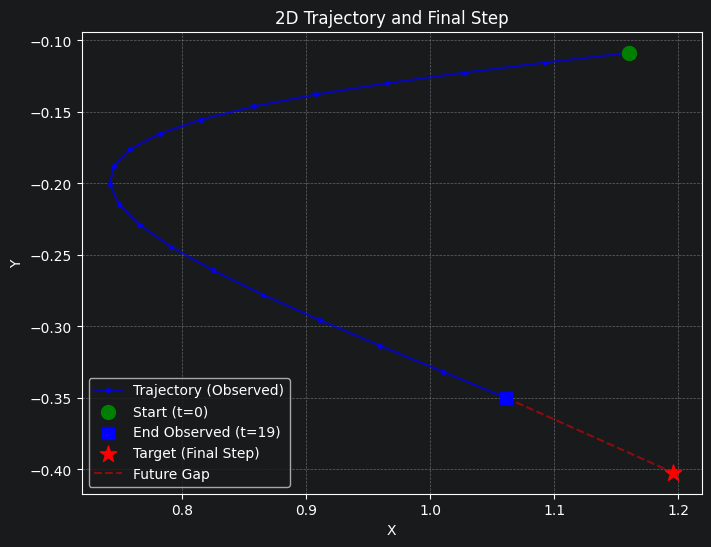

<Axes: title={'center': '2D Trajectory and Final Step'}, xlabel='X', ylabel='Y'>

In [2]:
class RandomTrajectories(Dataset):

    def __init__(self, n_tracks, n_timesteps, range_pos=[600,600], dim_coordinates=2, noise_level=5,
                 forward_steps=3, prob_acceleration=0.3, transform=None, target_transform=None):

        self.pos = np.random.randint([0 for i in range(dim_coordinates)], [range_pos[i] for i in range(dim_coordinates)],[n_tracks,dim_coordinates])
        self.linear_speed = np.random.randint(-20,20, [n_tracks,dim_coordinates])
        self.angular_speed = np.random.uniform(-4,4, [n_tracks, dim_coordinates])
        self.angular_radius = np.random.randint(1,100, [n_tracks, dim_coordinates])
        self.angular_acceleration = np.random.uniform(-2, 2, [n_tracks, dim_coordinates])
        acceleration_allowed = np.random.uniform(0,1,[n_tracks]) >  prob_acceleration
        self.angular_acceleration[acceleration_allowed] = 0
        self.angular_radius_acceleration = np.random.randint(1, 50, [n_tracks, dim_coordinates])
        self.n_timesteps = n_timesteps
        self.n_tracks = n_tracks
        self.noise_level = noise_level
        self.forward_steps = forward_steps
        self.freq = 0.05
        self.transform = transform
        self.target_transform = target_transform

    def __len__(self):
        return self.n_tracks

    def __getitem__(self, idx):
        t = np.arange(self.n_timesteps + self.forward_steps)[:, np.newaxis] * self.freq
        linear = self.linear_speed[idx] * t
        angular = self.angular_radius[idx] * np.sin(self.angular_speed[idx] * t)
        acc = self.angular_radius_acceleration[idx] * np.sin(self.angular_acceleration[idx] * t)

        traj = self.pos[idx] + linear + angular + acc
        if self.noise_level > 0:
            traj = traj + np.random.uniform(-self.noise_level, self.noise_level, traj.shape)

        data = torch.tensor(traj[:self.n_timesteps], dtype=torch.float32)
        target = torch.tensor(traj[self.n_timesteps + self.forward_steps - 1], dtype=torch.float32)

        if self.transform is not None:
            data = self.transform(data)
        if self.target_transform is not None:
            target = self.target_transform(target)

        return data, target

class NormalizeTrajectory:
    """
    Transformation to normalize trajectory data with given mean and standard deviation.
    """
    def __init__(self, mean: float = 300.0, std: float = 175.0):
        self.mean = mean
        self.std = std

    def __call__(self, tensor):
        return (tensor - self.mean) / self.std

    def __repr__(self):
        return f"{self.__class__.__name__}(mean={self.mean}, std={self.std})"


def plot_trajectory(trajectory, target, prediction=None, title="2D Trajectory and Final Step", ax=None, show=True):
    """
    Plots a 2D trajectory generated by RandomTrajectories and the position of the final step.

    Parameters:
    - trajectory: Tensor or ndarray of shape (T, 2) containing sequential (x, y) coordinates.
    - target: Tensor or ndarray of shape (2,) containing the final step coordinate.
    - prediction: Optional Tensor or ndarray of shape (2,) containing the predicted coordinate.
    - title: Title for the plot.
    - ax: Optional matplotlib Axes object to plot on.
    - show: Whether to display the plot with plt.show().
    """
    if isinstance(trajectory, torch.Tensor):
        trajectory = trajectory.detach().cpu().numpy()
    if isinstance(target, torch.Tensor):
        target = target.detach().cpu().numpy()
    if prediction is not None and isinstance(prediction, torch.Tensor):
        prediction = prediction.detach().cpu().numpy()

    created_fig = False
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))
        created_fig = True

    # Plot observed trajectory
    ax.plot(trajectory[:, 0], trajectory[:, 1], 'b.-', label='Trajectory (Observed)', alpha=0.7)
    ax.scatter(trajectory[0, 0], trajectory[0, 1], color='green', s=100, marker='o', label='Start (t=0)', zorder=5)
    ax.scatter(trajectory[-1, 0], trajectory[-1, 1], color='blue', s=80, marker='s', label=f'End Observed (t={len(trajectory)-1})', zorder=5)

    # Plot true final step target
    ax.scatter(target[0], target[1], color='red', s=150, marker='*', label='Target (Final Step)', zorder=6)
    ax.plot([trajectory[-1, 0], target[0]], [trajectory[-1, 1], target[1]], 'r--', alpha=0.5, label='Future Gap')

    # Plot prediction if provided
    if prediction is not None:
        ax.scatter(prediction[0], prediction[1], color='magenta', s=120, marker='X', label='Prediction', zorder=6)
        ax.plot([trajectory[-1, 0], prediction[0]], [trajectory[-1, 1], prediction[1]], 'm:', alpha=0.6)

    ax.set_title(title)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='best')

    if show and created_fig:
        plt.show()

    return ax

dataset = RandomTrajectories(n_tracks=50,n_timesteps=20,range_pos=[600,600],dim_coordinates=2, noise_level=0,
                 forward_steps = 3,transform=NormalizeTrajectory(),target_transform=NormalizeTrajectory())

positions = np.array([dataset[i][0] for i in range(50)])

idx_select = np.random.randint(0, dataset.n_tracks)
track,pos = dataset[idx_select]
plot_trajectory(track,pos)

In [26]:
def train_regression(network: nn.Module, optimizer: nn.Module,
                     train_loader: DataLoader, train_losses:list):
    network.train() #Mode
    train_loss = 0
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    network.to(device)
    criterion = nn.MSELoss()

    for batchId, (data, target) in enumerate(train_loader): #Iterate over batches
        data = data.to(device)
        target = target.to(device)

        #Feedforward pass
        optimizer.zero_grad()
        output_seq, output = network(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    length = len(train_loader.dataset)
    train_loss /= length
    train_losses += [train_loss]


#Testing
def test_regression(network: nn.Module, test_loader:DataLoader, test_losses:list):
    network.eval() #Test mode
    test_loss = 0
    criterion = nn.MSELoss()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    with torch.no_grad():
        for data, target in test_loader:
            data = data.to(device)
            target = target.to(device)
            output_seq,output = network(data)

            loss = criterion(output, target)
            test_loss += loss.item()
    length = len(test_loader.dataset)
    test_loss /= length
    test_losses.append(test_loss)
    return test_losses



In [55]:

transform = NormalizeTrajectory(mean=300.0, std=175.0)

train_dataset = RandomTrajectories(n_tracks=1000, n_timesteps=20, forward_steps=3,transform=transform,target_transform=transform , noise_level=2)
test_dataset = RandomTrajectories(n_tracks=200, n_timesteps=20, forward_steps=3,transform=transform,target_transform=transform , noise_level=2)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

model = LSTMNetwork(input_dim=2, hidden_dim=64, iterations=20, output_dim=2)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
epochs = 10
optimizer = optim.Adam(model.parameters(), lr=0.001)

train_losses = []
test_losses = []
for epoch in tqdm(range(epochs)):
    train_regression(model, optimizer, train_loader, train_losses)
    test_regression(model, test_loader, test_losses)
    print(f"Epoch {epoch + 1}/{epochs} - Train Loss: {train_losses[-1]:.4f} - Test Loss: {test_losses[-1]:.4f}")



  5%|▌         | 1/20 [00:00<00:07,  2.62it/s]

Epoch 1/20 - Train Loss: 0.0002 - Test Loss: 0.0002


 10%|█         | 2/20 [00:00<00:06,  2.72it/s]

Epoch 2/20 - Train Loss: 0.0002 - Test Loss: 0.0002


 15%|█▌        | 3/20 [00:01<00:06,  2.72it/s]

Epoch 3/20 - Train Loss: 0.0002 - Test Loss: 0.0002


... (30 outputs left out)

 95%|█████████▌| 19/20 [00:08<00:00,  2.09it/s]

Epoch 19/20 - Train Loss: 0.0001 - Test Loss: 0.0001


100%|██████████| 20/20 [00:08<00:00,  2.33it/s]

Epoch 20/20 - Train Loss: 0.0001 - Test Loss: 0.0001


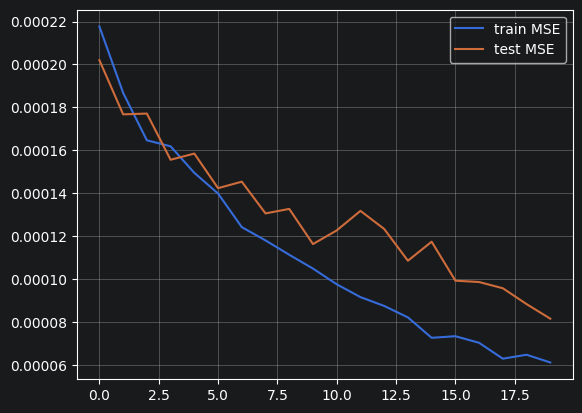

In [56]:
time = np.arange(epochs)
plt.plot(time,train_losses,label='train MSE')
plt.plot(time,test_losses,label='test MSE')
plt.grid()
plt.legend()

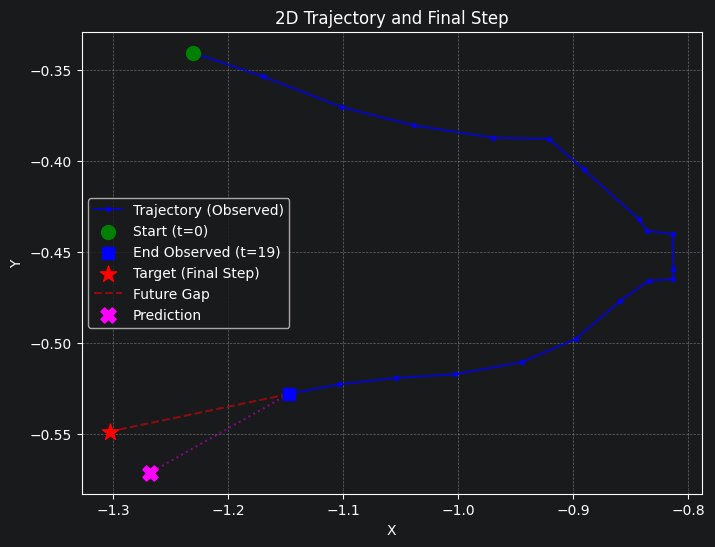

<Axes: title={'center': '2D Trajectory and Final Step'}, xlabel='X', ylabel='Y'>

In [59]:
(data, target) = next(iter(train_loader))
data = data.to(device)
target = target.to(device)
hs, pred = model(data)
track_sample = data[0].detach().cpu()
pos_sample = target[0].detach().cpu()
pred_sample = pred[0].detach().cpu()
plot_trajectory(track_sample,pos_sample,pred_sample)

In [6]:
class FeedForwardNetwork(nn.Module):
    """
    FeedForward network that receives a signal of dims [batch_size, sequence, input_dim],
    reshapes it to [batch_size, sequence * input_dim], and returns (features, pred).
    """
    ###### CODE HERE ######


def EvaluateFeedForwardNetwork():
    input_dim = 10
    hidden_dim = 11
    sequence_size = 12
    n_classes = 13
    batch_size = 9
    model = FeedForwardNetwork(input_dim=input_dim, hidden_dim=hidden_dim, iterations=sequence_size, output_dim=n_classes)

    data_sample = torch.rand(batch_size, sequence_size, input_dim)
    feat, pred = model(data_sample)
    assert feat.size()[0] == batch_size, "Batch size should remain constant."
    assert feat.size()[1] == hidden_dim, "Feature dimension should match hidden_dim."
    assert pred.size()[0] == batch_size, "Batch size should remain constant."
    assert pred.size()[1] == n_classes, "Prediction should match number of classes."
    print("Successful check for FeedForward Network")



EvaluateFeedForwardNetwork()


In [67]:

transform = NormalizeTrajectory(mean=300.0, std=175.0)

train_dataset = RandomTrajectories(n_tracks=1000, n_timesteps=20, forward_steps=3,transform=transform,target_transform=transform , noise_level=2)
test_dataset = RandomTrajectories(n_tracks=200, n_timesteps=20, forward_steps=3,transform=transform,target_transform=transform , noise_level=2)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

model = FeedForwardNetwork(input_dim=2, hidden_dim=64, iterations=20, output_dim=2)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
epochs = 20
optimizer = optim.Adam(model.parameters(), lr=0.0001)

train_losses = []
test_losses = []
for epoch in tqdm(range(epochs)):
    train_regression(model, optimizer, train_loader, train_losses)
    test_regression(model, test_loader, test_losses)
    print(f"Epoch {epoch + 1}/{epochs} - Train Loss: {train_losses[-1]:.4f} - Test Loss: {test_losses[-1]:.4f}")



 15%|█▌        | 3/20 [00:00<00:01, 11.79it/s]

Epoch 1/20 - Train Loss: 0.0015 - Test Loss: 0.0015
Epoch 2/20 - Train Loss: 0.0014 - Test Loss: 0.0015
Epoch 3/20 - Train Loss: 0.0014 - Test Loss: 0.0014


 35%|███▌      | 7/20 [00:00<00:00, 14.76it/s]

Epoch 4/20 - Train Loss: 0.0014 - Test Loss: 0.0014
Epoch 5/20 - Train Loss: 0.0013 - Test Loss: 0.0014
Epoch 6/20 - Train Loss: 0.0013 - Test Loss: 0.0013
Epoch 7/20 - Train Loss: 0.0013 - Test Loss: 0.0013


 55%|█████▌    | 11/20 [00:00<00:00, 15.11it/s]

Epoch 8/20 - Train Loss: 0.0012 - Test Loss: 0.0013
Epoch 9/20 - Train Loss: 0.0012 - Test Loss: 0.0012
Epoch 10/20 - Train Loss: 0.0011 - Test Loss: 0.0012
Epoch 11/20 - Train Loss: 0.0011 - Test Loss: 0.0012


... (2 outputs left out)

 85%|████████▌ | 17/20 [00:01<00:00, 13.32it/s]

Epoch 15/20 - Train Loss: 0.0010 - Test Loss: 0.0010
Epoch 16/20 - Train Loss: 0.0009 - Test Loss: 0.0010
Epoch 17/20 - Train Loss: 0.0009 - Test Loss: 0.0009


100%|██████████| 20/20 [00:01<00:00, 13.27it/s]

Epoch 18/20 - Train Loss: 0.0008 - Test Loss: 0.0009
Epoch 19/20 - Train Loss: 0.0008 - Test Loss: 0.0009
Epoch 20/20 - Train Loss: 0.0008 - Test Loss: 0.0008


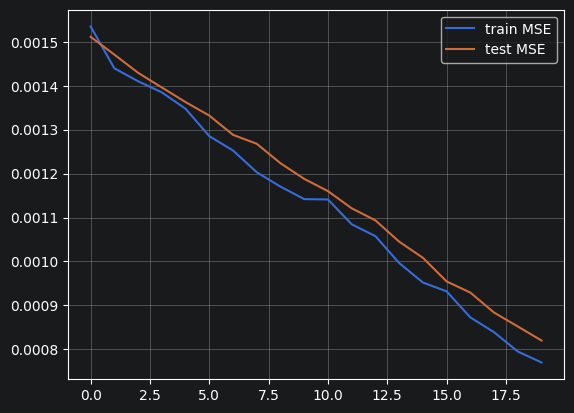

In [68]:
time = np.arange(epochs)
plt.plot(time,train_losses,label='train MSE')
plt.plot(time,test_losses,label='test MSE')
plt.grid()
plt.legend()

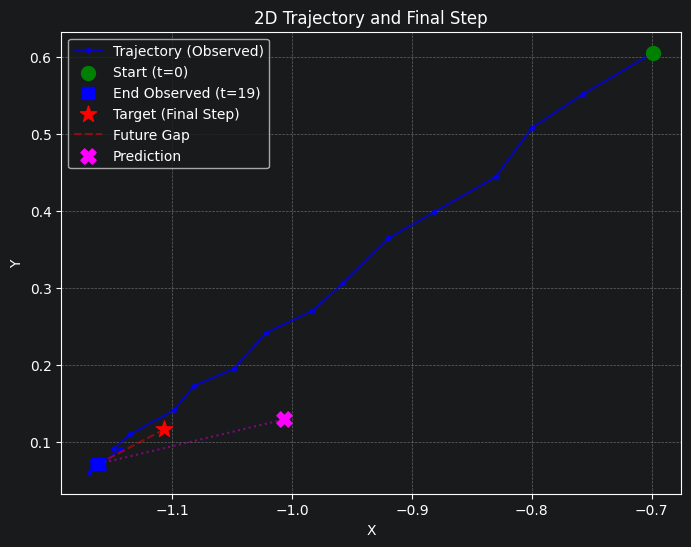

<Axes: title={'center': '2D Trajectory and Final Step'}, xlabel='X', ylabel='Y'>

In [71]:
(data, target) = next(iter(train_loader))
data = data.to(device)
target = target.to(device)
hs, pred = model(data)
track_sample = data[0].detach().cpu()
pos_sample = target[0].detach().cpu()
pred_sample = pred[0].detach().cpu()
plot_trajectory(track_sample,pos_sample,pred_sample)

# Parte 4: Entrenamiento en audio
Descargue la base de datos ESC-50:
https://www.kaggle.com/datasets/ludovick/esc50dataset/code
1. Utilice la función extract_and_save_mfcc_dataset para generar una base de datos de coeficientes MFCC a partir de ESC-50.
2. Defina una red LSTM con múltiples módulos LSTM y entrénela.
3. Defina una clase que utilice la LSTM bidireccional de PyTorch (nn.LSTM con bidirectional=True) y entrene esta red Bi-LSTM.
4. Entrene una red Feed Forward que reciba la secuencia completa como un único vector de entrada (es decir, sin procesar la secuencia paso a paso).
5. Compare el accuracy y la loss de los tres modelos.
6. Genere la matriz de confusión de cada uno de los tres modelos.
7. Analice algunos ejemplos de la clase con más errores.

In [20]:
def generate_MFCC_signal(filepath, winlen=0.1, numcep=13, winstep=0.05):
    """
    Computes MFCC features for an audio wav file.
    winlen and winstep can be specified in seconds (e.g. 0.1, 0.05) or ms (e.g. 100, 50).
    """
    if winlen > 1.0:
        winlen = winlen / 1000.0
    if winstep > 1.0:
        winstep = winstep / 1000.0

    file_fs, file_audio = wavfile.read(filepath)
    nfft = int(2 ** np.ceil(np.log2(file_fs * winlen)))
    file_audio = file_audio.astype(np.float32)
    std_val = file_audio.std()
    if std_val > 1e-8:
        file_audio = (file_audio - file_audio.mean()) / std_val
    else:
        file_audio = file_audio - file_audio.mean()

    file_mfcc = mfcc(
        file_audio, file_fs,
        winlen=winlen, winstep=winstep, numcep=numcep, nfft=nfft)
    file_mfcc = file_mfcc.astype(np.float32)
    return file_mfcc


def split_audio_dataset(anns_df: pd.DataFrame, test_size: float = 0.2, random_state: int = 42):
    """
    Split randomly the demo audio files into training and testing sets.
    """
    if random_state is not None:
        np.random.seed(random_state)
    indices = np.random.permutation(len(anns_df))
    split_point = int(len(anns_df) * (1.0 - test_size))
    train_idx = indices[:split_point]
    test_idx = indices[split_point:]
    train_df = anns_df.iloc[train_idx].reset_index(drop=True)
    test_df = anns_df.iloc[test_idx].reset_index(drop=True)
    return train_df, test_df


def extract_and_save_mfcc_dataset(
    path_wavs: str = 'data/ESC-50-master/audio/',
    path_anns: str = 'data/ESC-50-master/meta/esc50.csv',
    train_path: str = 'data/train.npz',
    test_path: str = 'data/test.npz',
    test_size: float = 0.2,
    random_state: int = 42,
    winlen: float = 0.1,
    winstep: float = 0.05,
    numcep: int = 13
):
    """
    Uses generate_MFCC_signal to compute MFCC features for audio files,
    splits them randomly, and saves training and testing datasets as .npz files.
    """
    anns = pd.read_csv(path_anns)
    train_df, test_df = split_audio_dataset(anns, test_size=test_size, random_state=random_state)

    def extract_set(df, desc):
        features = []
        targets = []
        for _, row in tqdm(df.iterrows(), total=len(df), desc=desc):
            wav_file = os.path.join(path_wavs, row['filename'])
            feat = generate_MFCC_signal(wav_file, winlen=winlen, winstep=winstep, numcep=numcep)
            features.append(feat)
            targets.append(row['target'])
        return np.array(features, dtype=np.float32), np.array(targets, dtype=np.int64)

    print("Extracting MFCC features for training set...")
    train_data, train_targets = extract_set(train_df, "Train MFCC")
    os.makedirs(os.path.dirname(train_path) or '.', exist_ok=True)
    np.savez(train_path, data=train_data, targets=train_targets)
    print(f"Saved training dataset to {train_path} with data shape {train_data.shape} and targets shape {train_targets.shape}")

    print("Extracting MFCC features for testing set...")
    test_data, test_targets = extract_set(test_df, "Test MFCC")
    os.makedirs(os.path.dirname(test_path) or '.', exist_ok=True)
    np.savez(test_path, data=test_data, targets=test_targets)
    print(f"Saved testing dataset to {test_path} with data shape {test_data.shape} and targets shape {test_targets.shape}")

    return train_data, train_targets, test_data, test_targets
path_wavs = 'data/ESC-50-master/audio/'
path_anns = 'data/ESC-50-master/meta/esc50.csv'
train_path = 'data/train.npz'
test_path = 'data/test.npz'
extract_and_save_mfcc_dataset(
    path_wavs=path_wavs,
    path_anns=path_anns,
    train_path=train_path,
    test_path=test_path,
    test_size=0.2,
    random_state=42
)


In [8]:
def EvaluateMultiModule():
    input_dim = 10
    hidden_dim = 11
    sequence_size = 12
    batch_size = 9
    num_layers = 3
    model = MultiModuleLSTM(input_dim, hidden_dim, sequence_size, num_layers=num_layers)
    model.eval()
    data_sample = torch.rand(batch_size, sequence_size, input_dim)
    h = torch.zeros(num_layers, batch_size, hidden_dim)
    carrier = torch.zeros(num_layers, batch_size, hidden_dim)
    output, carrier = model(data_sample, h, carrier)
    assert output.size()[0] == batch_size, "Batch size should remain constant."
    assert output.size()[1] == sequence_size, "Sequence length must be preserved."
    assert output.size()[2] == hidden_dim, "Inconsistent hidden dimension."
    print("Successful check for MultiModule LSTM")


class MultiModuleLSTM(nn.Module):
    """
    LSTM class composed of multiple ModuleLSTM layers stacked sequentially.
    """
    def __init__(self, input_dim: int = 20, hidden_dim: int = 32, iterations: int = 100, num_layers: int = 2):
        super(MultiModuleLSTM, self).__init__()
        ###### CODE HERE ######

    def forward(self, x, h, carrier):
        ###### CODE HERE ######


class AudioMFCCDataset(Dataset):
    """
    Dataset class for loading audio MFCC features and class targets from .npz files or arrays.
    """
    def __init__(self, data_or_path, targets=None):
        if isinstance(data_or_path, str):
            npz = np.load(data_or_path)
            if 'data' in npz:
                self.data = npz['data']
            elif 'features' in npz:
                self.data = npz['features']
            else:
                self.data = npz[npz.files[0]]

            if 'targets' in npz:
                self.targets = npz['targets']
            elif 'labels' in npz:
                self.targets = npz['labels']
            else:
                self.targets = npz[npz.files[1]]
        else:
            self.data = data_or_path
            self.targets = targets

        self.data = torch.as_tensor(self.data, dtype=torch.float32)
        self.targets = torch.as_tensor(self.targets, dtype=torch.long)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx], self.targets[idx]

def train_classification(model: nn.Module, loader: DataLoader, optimizer, train_loss: list, train_acc: list, device='cpu'):
    """
    Runs one pass over the loader (training if an optimizer is given).
    """
    model.train(True)
    total_ce = 0.
    n_batches = 0
    correct, n_positive = 0, 0
    loss_fn = nn.CrossEntropyLoss()

    for data, targets in loader:
        data = data.to(device)
        targets = targets.to(device)
        out = model(data)
        if isinstance(out, tuple):
            pred = out[1]
        else:
            pred = out
        ce_loss = loss_fn(pred, targets)

        optimizer.zero_grad()
        ce_loss.backward()
        optimizer.step()

        total_ce += ce_loss.item()
        n_batches += 1

        correct += (pred.argmax(dim=1) == targets).sum().item()
        n_positive += len(targets)

    epoch_loss = total_ce / max(n_batches, 1)
    epoch_acc = correct / max(n_positive, 1)
    train_loss.append(epoch_loss)
    train_acc.append(epoch_acc)
    return train_loss, train_acc


def test_classification(model: nn.Module, loader: DataLoader, test_loss: list, test_acc: list, device='cpu'):
    """
    Runs one pass over the test loader in evaluation mode and records loss and accuracy.
    """
    model.eval()
    total_ce = 0.
    n_batches = 0
    correct, n_positive = 0, 0
    loss_fn = nn.CrossEntropyLoss()

    with torch.no_grad():
        for data, targets in loader:
            data = data.to(device)
            targets = targets.to(device)
            out = model(data)
            if isinstance(out, tuple):
                pred = out[1]
            else:
                pred = out
            ce_loss = loss_fn(pred, targets)

            total_ce += ce_loss.item()
            n_batches += 1

            correct += (pred.argmax(dim=1) == targets).sum().item()
            n_positive += len(targets)

    epoch_loss = total_ce / max(n_batches, 1)
    epoch_acc = correct / max(n_positive, 1)
    test_loss.append(epoch_loss)
    test_acc.append(epoch_acc)
    return test_loss, test_acc


EvaluateMultiModule()

Successful check for MultiModule LSTM
Successful check for FeedForward Network


In [17]:
train_path = 'data/train.npz'
test_path = 'data/test.npz'
epochs = 20
batch_size = 32
lr = 0.0001
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
train_dataset = AudioMFCCDataset(train_path)
test_dataset = AudioMFCCDataset(test_path)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

sample_x, sample_y = train_dataset[0]
seq_len, input_dim = sample_x.shape
n_classes = int(max(train_dataset.targets.max().item(), test_dataset.targets.max().item()) + 1)

print("\n" + "="*50)
print("Evaluating Architectures:")

print("="*50)

print(f"\n--- Training Multi-Module LSTM Network ({epochs} epochs) ---")
lstm_model = LSTMNetwork(input_dim=input_dim, hidden_dim=64, iterations=seq_len, output_dim=n_classes, num_layers=2)

lstm_model.to(device)
optimizer = optim.Adam(lstm_model.parameters(), lr=lr)

train_losses = []
train_accs = []
test_losses = []
test_accs = []

for epoch in tqdm(range(epochs), desc=f"Training {lstm_model.__class__.__name__}"):
    train_classification(lstm_model, train_loader, optimizer, train_losses, train_accs, device=device)
    test_classification(lstm_model, test_loader, test_losses, test_accs, device=device)
    print(f"Epoch {epoch + 1:02d}/{epochs:02d} | "
          f"Train Loss: {train_losses[-1]:.4f} - Train Acc: {train_accs[-1]*100:.2f}% | "
          f"Test Loss: {test_losses[-1]:.4f} - Test Acc: {test_accs[-1]*100:.2f}%")



# Parte 5: Análisis
1. ¿Generó alguna mejora el uso de la red Bi-LSTM? Comente por qué.
2. ¿Los errores de clasificación fueron consistentes entre los distintos modelos? Justifique.
3. Dado un numero fijo de pesos ¿Que red necesita mas capas/modulos? Justifique.